# NB5c — ML บน FOOOF features

จำแนกว่าการบันทึกไหนคือก่อนหรือหลังทำงาน จากผลต่างของคนคนเดียวกัน
ใช้ GroupKFold แบ่งตามคน และสลับเครื่องหมายครึ่งหนึ่งเพื่อให้สองคลาสสมดุล

**ผลที่ใช้จริงคือบล็อก v4 (เซลล์ 14–19)** ไฟล์ `outputs/nb5c_v4_summary.csv`
ซึ่ง NB6 อ่านต่อ รุ่นก่อนหน้าเก็บไว้เพื่อแสดงผลของการตั้งค่า

| รุ่น | ข้อมูล | ชุด feature | C (ท้ายทอย + aperiodic) | ดีที่สุด |
|---|---|---|---|---|
| v2 | ท้ายทอย, fit 1–40 | A–D | 0.775 | C 0.775 |
| v3 | 3 บริเวณ, fit 1–30 | A–E | 0.739 | E 0.803 |
| **v4** | 3 บริเวณ, ICA 0.9 | A–E | **0.746** | **E 0.819** |

ชุด C ตกจาก **0.775 (v2) เหลือ 0.739 (v3)** เมื่อแก้ช่วง fit ให้ถูกต้อง
แล้วขึ้นมาเป็น **0.746 (v4)** เมื่อเปลี่ยน ICA ให้ลบ muscle น้อยลง
การตกครั้งแรกสอดคล้องกับที่ว่าตัวเลขของ v2 ถูกดันขึ้นจากช่วง fit ที่ลำเอียง
แต่ยังสรุปเป็นเหตุเป็นผลตรง ๆ ไม่ได้ เพราะ v2 กับ v3 อ่าน feature คนละไฟล์
และจำนวนคู่ก็ไม่เท่ากัน จึงมีโอกาสที่มีอย่างอื่นเปลี่ยนไปด้วย
ส่วนการขึ้นครั้งหลังเป็นผลของ ICA คนละเรื่องกัน อย่าเอาสองอย่างมารวมกัน

ตัวเลขที่รายงานในสไลด์คือ **ชุด E 0.819** ซึ่งมี **n = 1,206 คู่** ไม่ใช่ 1,213
(ชุด A B C ใช้แต่ขั้วท้ายทอย จึงเหลือ 1,213 คู่)

## v2 — รุ่นแรก (อย่าใช้ตัวเลขจากบล็อกนี้)

คำนวณจาก `fooof_features_v2.csv` ซึ่ง fit FOOOF ที่ 1–40 Hz บนข้อมูลที่กรองไว้ที่
40 Hz ทำให้ exponent ลำเอียง ตัวเลข 0.775 ที่บล็อกนี้พิมพ์ออกมาจึงสูงเกินจริง

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_score, permutation_test_score
warnings.filterwarnings('ignore')

df = pd.read_csv('outputs/fooof_features_v2.csv')
print(f"Loaded {len(df)} recordings")

# quality filter: exponent <= 0 = FOOOF fit ล้มเหลว (เป็นไปไม่ได้ทางสรีรวิทยา)
n0 = len(df)
df = df[df['ap_exponent'] > 0].copy()
print(f"Quality filter: dropped {n0-len(df)} rows (ap_exponent <= 0) → {len(df)} remain")

# pairing pre/post
pre  = df[df['condition'] == 'pre' ].set_index(['subject','task'])
post = df[df['condition'] == 'post'].set_index(['subject','task'])
merged = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
print(f"Paired: {len(merged)} pre/post pairs, {merged['subject'].nunique()} subjects")

# ผลต่าง post − pre (ค่าอยู่ใน log scale แล้ว ไม่ใช้ log ratio)
measures = ['low_alpha_rel', 'high_alpha_rel',
            'low_alpha_corr', 'high_alpha_corr',
            'low_alpha_corr_rel', 'high_alpha_corr_rel',
            'ap_exponent', 'ap_offset']
for m in measures:
    merged[f'd_{m}'] = merged[f'{m}_post'] - merged[f'{m}_pre']

print(merged[[f'd_{m}' for m in measures]].describe().round(4).to_string())

Loaded 2432 recordings
Quality filter: dropped 6 rows (ap_exponent <= 0) → 2426 remain
Paired: 1210 pre/post pairs, 607 subjects
       d_low_alpha_rel  d_high_alpha_rel  d_low_alpha_corr  d_high_alpha_corr  d_low_alpha_corr_rel  d_high_alpha_corr_rel  d_ap_exponent  d_ap_offset
count        1210.0000         1210.0000         1210.0000          1210.0000             1210.0000              1210.0000      1210.0000    1210.0000
mean            0.0245            0.0035            0.0902             0.0209                0.0330                -0.0073        -0.0341       0.0074
std             0.0677            0.0916            0.2162             0.2108                0.0942                 0.1297         0.2253       0.2692
min            -0.2679           -0.4521           -0.7499            -1.1168               -0.3106                -0.5262        -1.0497      -1.4812
25%            -0.0068           -0.0328           -0.0353            -0.0897               -0.0168                -

In [2]:
feat_sets = {
    'A\nrelative band':      ['d_low_alpha_rel',      'd_high_alpha_rel'],
    'B\ncorrected band':     ['d_low_alpha_corr',     'd_high_alpha_corr'],
    'C\ncorr + aperiodic':   ['d_low_alpha_corr',     'd_high_alpha_corr',
                              'd_ap_exponent',        'd_ap_offset'],
    'D\ncorr-relative':      ['d_low_alpha_corr_rel', 'd_high_alpha_corr_rel'],
}

def make_XyG(data, feat_cols, seed=42):
    """paired flip-sign: ครึ่งหนึ่งสลับเครื่องหมาย → label 0, อีกครึ่ง → label 1"""
    rng = np.random.default_rng(seed)
    X, y, g = [], [], []
    for _, row in data.iterrows():
        diffs = [row[c] for c in feat_cols]
        if any(not np.isfinite(v) for v in diffs):
            continue
        task_flag = float(row['task'] == 'EyesOpen')
        flip = rng.random() < 0.5
        X.append([-v if flip else v for v in diffs] + [task_flag])
        y.append(0 if flip else 1)
        g.append(row['subject'])
    return np.array(X), np.array(y), np.array(g)

gkf = GroupKFold(n_splits=5)
lr  = Pipeline([('sc', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

results_nb5c = {}
for name, feats in feat_sets.items():
    X, y, g = make_XyG(merged, feats)
    scores = cross_val_score(lr, X, y, groups=g, cv=gkf, scoring='f1')
    results_nb5c[name] = {'scores': scores, 'n': len(y), 'feats': feats}
    print(f"{name.replace(chr(10),' '):22s}  n={len(y):4d}  "
          f"F1={scores.mean():.3f} ± {scores.std():.3f}")

A relative band         n=1210  F1=0.655 ± 0.034
B corrected band        n=1210  F1=0.675 ± 0.033
C corr + aperiodic      n=1210  F1=0.775 ± 0.040
D corr-relative         n=1210  F1=0.633 ± 0.034


In [3]:
perm_results = {}
for name, feats in feat_sets.items():
    X, y, g = make_XyG(merged, feats)
    obs, perm_scores, p_val = permutation_test_score(
        lr, X, y, groups=g, cv=GroupKFold(5),
        scoring='f1', n_permutations=200, random_state=42, n_jobs=-1)
    perm_results[name] = {'F1': obs, 'p': p_val, 'chance': perm_scores.mean()}
    print(f"{name.replace(chr(10),' '):22s}  F1={obs:.3f}  "
          f"chance={perm_scores.mean():.3f}  p={p_val:.4f}")

print("\nNote: the empirical chance level exceeds 0.5 because sklearn permutes "
      "labels within each subject, and each subject contributes only 2 rows "
      "(EO/EC) — many permutations leave labels unchanged. This makes the test "
      "more conservative than a standard permutation test, so the reported "
      "p-values are upper bounds.")

A relative band         F1=0.655  chance=0.558  p=0.0050
B corrected band        F1=0.675  chance=0.575  p=0.0050
C corr + aperiodic      F1=0.775  chance=0.638  p=0.0050
D corr-relative         F1=0.633  chance=0.551  p=0.0050

Note: the empirical chance level exceeds 0.5 because sklearn permutes labels within each subject, and each subject contributes only 2 rows (EO/EC) — many permutations leave labels unchanged. This makes the test more conservative than a standard permutation test, so the reported p-values are upper bounds.


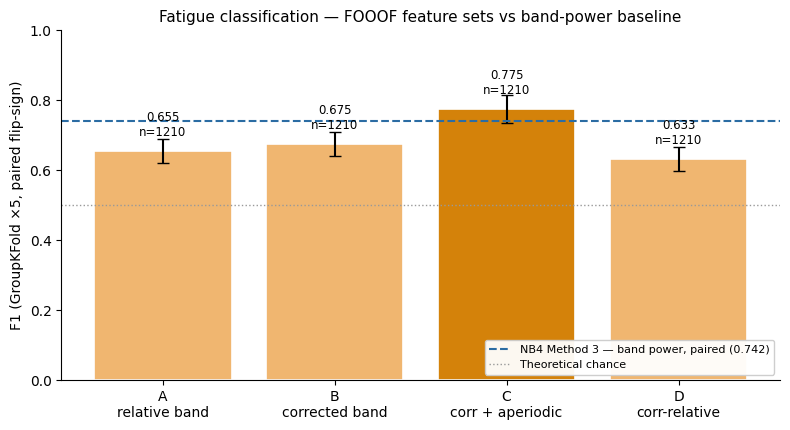

In [4]:
nb4_m3 = 0.742   # NB4 Method 3 (band power, paired) — เส้นอ้างอิงที่ถูกต้อง

labels = list(results_nb5c.keys())
vals   = [results_nb5c[k]['scores'].mean() for k in labels]
errs   = [results_nb5c[k]['scores'].std()  for k in labels]
ns     = [results_nb5c[k]['n'] for k in labels]
best   = int(np.argmax(vals))
colors = ['#d4820a' if i == best else '#f0b670' for i in range(len(labels))]

fig, ax = plt.subplots(figsize=(8, 4.4))
bars = ax.bar(labels, vals, yerr=errs, capsize=4,
              color=colors, edgecolor='white', linewidth=1.2)
ax.axhline(nb4_m3, color='#2b6ca3', linestyle='--', linewidth=1.5,
           label=f'NB4 Method 3 — band power, paired ({nb4_m3:.3f})')
ax.axhline(0.5, color='#999', linestyle=':', linewidth=1, label='Theoretical chance')

for bar, v, n in zip(bars, vals, ns):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.035,
            f'{v:.3f}\nn={n}', ha='center', va='bottom', fontsize=8.5)

ax.set_ylim(0, 1.0)
ax.set_ylabel('F1 (GroupKFold ×5, paired flip-sign)')
ax.set_title('Fatigue classification — FOOOF feature sets vs band-power baseline',
             fontsize=11)
ax.legend(loc='lower right', fontsize=8, framealpha=0.95)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('outputs/nb5c_comparison.png', dpi=150)
plt.show()

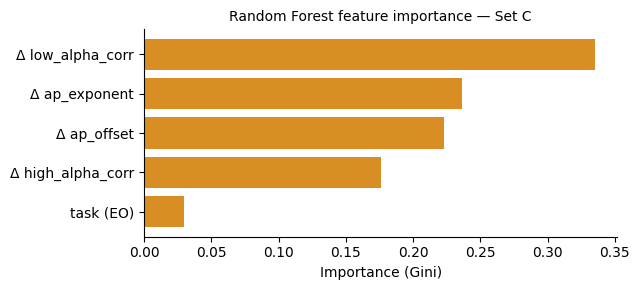

In [5]:
feats_c = feat_sets['C\ncorr + aperiodic']
X, y, g = make_XyG(merged, feats_c)

rf = Pipeline([('sc', StandardScaler()),
               ('clf', RandomForestClassifier(n_estimators=300, random_state=42))])
rf.fit(X, y)

names = [c.replace('d_', 'Δ ') for c in feats_c] + ['task (EO)']
imps  = rf.named_steps['clf'].feature_importances_
order = np.argsort(imps)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh([names[i] for i in order], imps[order], color='#d4820a', alpha=0.9)
ax.set_xlabel('Importance (Gini)')
ax.set_title('Random Forest feature importance — Set C', fontsize=10)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('outputs/nb5c_importance.png', dpi=150)
plt.show()

In [6]:
summary = pd.DataFrame([{
    'feature_set': k.replace('\n', ' — '),
    'n_features':  len(results_nb5c[k]['feats']) + 1,
    'n_pairs':     results_nb5c[k]['n'],
    'F1_mean':     results_nb5c[k]['scores'].mean(),
    'F1_std':      results_nb5c[k]['scores'].std(),
    'perm_chance': perm_results[k]['chance'],
    'perm_p':      perm_results[k]['p'],
} for k in results_nb5c])

print(summary.round(4).to_string(index=False))
print(f"\nBaseline — NB4 Method 3 (band power, all channels, paired): F1 = {nb4_m3:.3f}")

bk = summary.loc[summary['F1_mean'].idxmax()]
print(f"\nBest: {bk['feature_set']} — F1 = {bk['F1_mean']:.3f} "
      f"({'above' if bk['F1_mean'] > nb4_m3 else 'below'} NB4 baseline, "
      f"Δ = {bk['F1_mean']-nb4_m3:+.3f})")

summary.to_csv('outputs/nb5c_summary.csv', index=False)
print("\nSaved: outputs/nb5c_summary.csv, nb5c_comparison.png, nb5c_importance.png")

         feature_set  n_features  n_pairs  F1_mean  F1_std  perm_chance  perm_p
   A — relative band           3     1210   0.6548  0.0339       0.5583   0.005
  B — corrected band           3     1210   0.6749  0.0332       0.5750   0.005
C — corr + aperiodic           5     1210   0.7752  0.0404       0.6380   0.005
   D — corr-relative           3     1210   0.6327  0.0345       0.5512   0.005

Baseline — NB4 Method 3 (band power, all channels, paired): F1 = 0.742

Best: C — corr + aperiodic — F1 = 0.775 (above NB4 baseline, Δ = +0.033)

Saved: outputs/nb5c_summary.csv, nb5c_comparison.png, nb5c_importance.png


## v3 — ตั้งค่าตรงกับ Yang และขยายเป็น 3 บริเวณ (ถูกแทนที่แล้ว)

เพิ่มชุด D และ E ซึ่งใช้ทั้งสามบริเวณ และเป็นครั้งแรกที่เห็นว่าการขยายบริเวณ
ให้ผลพอ ๆ กับการเพิ่ม aperiodic

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_score, permutation_test_score
warnings.filterwarnings('ignore')

SRC = 'outputs/fooof_features_v3.csv'      # พรุ่งนี้เปลี่ยนเป็น v4 ถ้า v4 เสร็จ

df = pd.read_csv(SRC)
n0 = len(df)
df = df[df['ap_exponent'] > 0].copy()
print(f"{SRC}: {n0} rows → {len(df)} after quality filter")

meas = ['low_alpha_corr', 'high_alpha_corr',
        'low_alpha_rel',  'high_alpha_rel',
        'low_alpha_corr_rel', 'high_alpha_corr_rel',
        'ap_exponent', 'ap_offset']

# long → wide: หนึ่งแถวต่อ (subject, task, condition) คอลัมน์เป็น measure_region
w = df.pivot_table(index=['subject','task','condition'], columns='region', values=meas)
w.columns = [f'{m}_{r}' for m, r in w.columns]
w = w.reset_index()
print(f"wide: {w.shape[0]} rows × {w.shape[1]} cols")

pre  = w[w['condition'] == 'pre' ].drop(columns='condition').set_index(['subject','task'])
post = w[w['condition'] == 'post'].drop(columns='condition').set_index(['subject','task'])
idx  = pre.index.intersection(post.index)
d    = (post.loc[idx] - pre.loc[idx]).reset_index()      # ผลต่าง post − pre

print(f"paired: {len(d)} pairs, {d['subject'].nunique()} subjects")
print(f"NaN cells: {d.isna().sum().sum()}")

outputs/fooof_features_v3.csv: 7296 rows → 7273 after quality filter
wide: 2432 rows × 27 cols
paired: 1216 pairs, 608 subjects
NaN cells: 176


In [8]:
REG = ['frontal', 'central', 'occipital']

feat_sets = {
    'A\nrel · occ':        [f'{m}_occipital' for m in ['low_alpha_rel','high_alpha_rel']],
    'B\ncorr · occ':       [f'{m}_occipital' for m in ['low_alpha_corr','high_alpha_corr']],
    'C\ncorr+aper · occ':  [f'{m}_occipital' for m in ['low_alpha_corr','high_alpha_corr',
                                                        'ap_exponent','ap_offset']],
    'D\ncorr+aper · 3reg': [f'{m}_{r}' for r in REG
                            for m in ['low_alpha_corr','high_alpha_corr',
                                      'ap_exponent','ap_offset']],
    'E\nall · 3reg':       [f'{m}_{r}' for r in REG for m in meas],
}
for k, v in feat_sets.items():
    print(f"{k.replace(chr(10),' '):22s} {len(v):2d} features")

def make_XyG(data, cols, seed=42):
    rng = np.random.default_rng(seed)
    X, y, g = [], [], []
    for _, row in data.iterrows():
        vals = [row[c] for c in cols]
        if any(not np.isfinite(v) for v in vals):
            continue
        tf = float(row['task'] == 'EyesOpen')
        flip = rng.random() < 0.5
        X.append([-v if flip else v for v in vals] + [tf])
        y.append(0 if flip else 1)
        g.append(row['subject'])
    return np.array(X), np.array(y), np.array(g)

gkf = GroupKFold(n_splits=5)
lr  = Pipeline([('sc', StandardScaler()),
                ('clf', LogisticRegression(max_iter=2000, random_state=42))])
rf  = Pipeline([('sc', StandardScaler()),
                ('clf', RandomForestClassifier(n_estimators=300, random_state=42))])

results = {}
for name, cols in feat_sets.items():
    X, y, g = make_XyG(d, cols)
    s_lr = cross_val_score(lr, X, y, groups=g, cv=gkf, scoring='f1')
    s_rf = cross_val_score(rf, X, y, groups=g, cv=gkf, scoring='f1')
    results[name] = {'lr': s_lr, 'rf': s_rf, 'n': len(y), 'k': len(cols)}
    print(f"{name.replace(chr(10),' '):22s} n={len(y):4d}  "
          f"LR={s_lr.mean():.3f}±{s_lr.std():.3f}   RF={s_rf.mean():.3f}±{s_rf.std():.3f}")

A rel · occ             2 features
B corr · occ            2 features
C corr+aper · occ       4 features
D corr+aper · 3reg     12 features
E all · 3reg           24 features
A rel · occ            n=1215  LR=0.684±0.030   RF=0.662±0.026
B corr · occ           n=1215  LR=0.710±0.033   RF=0.673±0.034
C corr+aper · occ      n=1215  LR=0.739±0.031   RF=0.727±0.024
D corr+aper · 3reg     n=1196  LR=0.784±0.037   RF=0.776±0.024
E all · 3reg           n=1196  LR=0.803±0.023   RF=0.781±0.020


In [9]:
perm = {}
for name, cols in feat_sets.items():
    X, y, g = make_XyG(d, cols)
    obs, ps, p = permutation_test_score(
        lr, X, y, groups=g, cv=GroupKFold(5), scoring='f1',
        n_permutations=200, random_state=42, n_jobs=-1)
    perm[name] = {'F1': obs, 'chance': ps.mean(), 'p': p}
    print(f"{name.replace(chr(10),' '):22s} F1={obs:.3f}  chance={ps.mean():.3f}  p={p:.4f}")

print("\nNote: empirical chance exceeds 0.5 because sklearn permutes labels within "
      "each subject, and each subject contributes only 2 rows (EO/EC) — many "
      "permutations leave labels unchanged. The test is therefore more conservative "
      "than a standard permutation test and the p-values are upper bounds.")

A rel · occ            F1=0.684  chance=0.575  p=0.0050
B corr · occ           F1=0.710  chance=0.593  p=0.0050
C corr+aper · occ      F1=0.739  chance=0.625  p=0.0050
D corr+aper · 3reg     F1=0.784  chance=0.636  p=0.0050
E all · 3reg           F1=0.803  chance=0.632  p=0.0050

Note: empirical chance exceeds 0.5 because sklearn permutes labels within each subject, and each subject contributes only 2 rows (EO/EC) — many permutations leave labels unchanged. The test is therefore more conservative than a standard permutation test and the p-values are upper bounds.


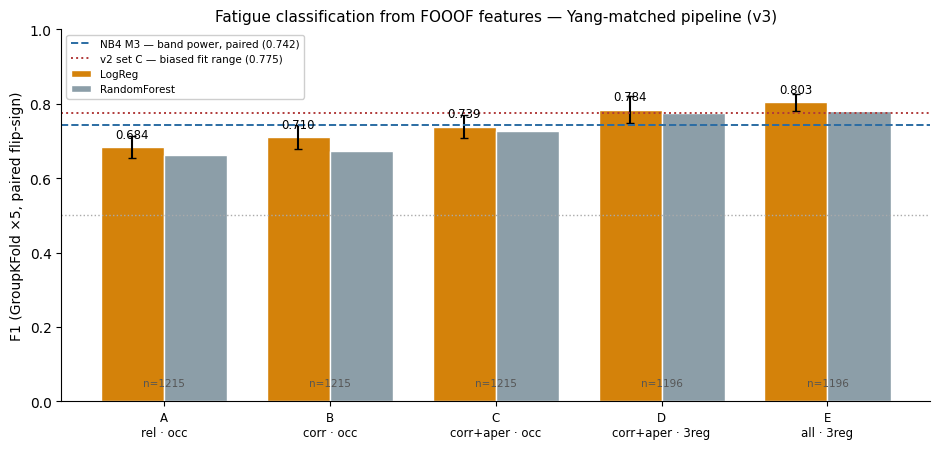

In [10]:
NB4_M3   = 0.742     # band power, paired (NB4 Method 3)
V2_SET_C = 0.775     # ผลเดิมบน v2 ที่ fit ชนขอบ filter — ไว้เทียบ

labels = list(results.keys())
vlr = [results[k]['lr'].mean() for k in labels]
elr = [results[k]['lr'].std()  for k in labels]
vrf = [results[k]['rf'].mean() for k in labels]
ns  = [results[k]['n'] for k in labels]
x   = np.arange(len(labels)); wd = 0.38

fig, ax = plt.subplots(figsize=(9.5, 4.6))
b1 = ax.bar(x - wd/2, vlr, wd, yerr=elr, capsize=3, label='LogReg',
            color='#d4820a', edgecolor='white')
b2 = ax.bar(x + wd/2, vrf, wd, label='RandomForest',
            color='#8c9ea8', edgecolor='white')
ax.axhline(NB4_M3, color='#2b6ca3', ls='--', lw=1.4,
           label=f'NB4 M3 — band power, paired ({NB4_M3:.3f})')
ax.axhline(V2_SET_C, color='#b03a3a', ls=':', lw=1.4,
           label=f'v2 set C — biased fit range ({V2_SET_C:.3f})')
ax.axhline(0.5, color='#aaa', ls=':', lw=1)

for bar, v in zip(b1, vlr):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.025, f'{v:.3f}',
            ha='center', fontsize=8.5)
for i, n in enumerate(ns):
    ax.text(i, 0.04, f'n={n}', ha='center', fontsize=7.5, color='#555')

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylim(0, 1); ax.set_ylabel('F1 (GroupKFold ×5, paired flip-sign)')
ax.set_title('Fatigue classification from FOOOF features — Yang-matched pipeline (v3)',
             fontsize=11)
ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/nb5c_v3_comparison.png', dpi=150); plt.show()

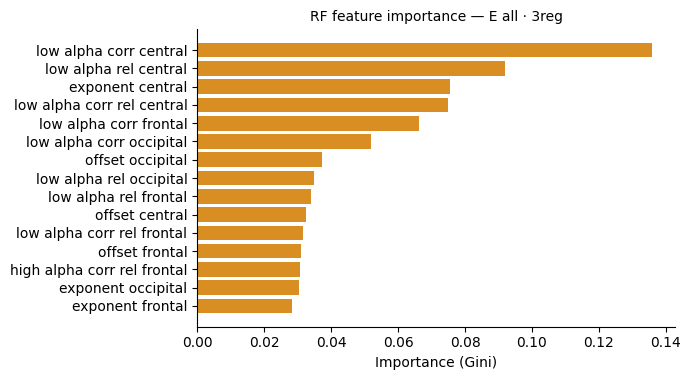

         feature_set  n_features  n_pairs  F1_LR  F1_LR_sd  F1_RF  perm_chance  perm_p
       A — rel · occ           2     1215 0.6842    0.0296 0.6623       0.5754   0.005
      B — corr · occ           2     1215 0.7105    0.0328 0.6733       0.5929   0.005
 C — corr+aper · occ           4     1215 0.7386    0.0309 0.7267       0.6247   0.005
D — corr+aper · 3reg          12     1196 0.7844    0.0367 0.7761       0.6355   0.005
      E — all · 3reg          24     1196 0.8035    0.0232 0.7809       0.6323   0.005

Best: E all · 3reg — LR F1 = 0.803
Reference — NB4 Method 3 (band power, all channels, paired): 0.742


In [11]:
best = max(results, key=lambda k: results[k]['lr'].mean())
cols = feat_sets[best]
X, y, g = make_XyG(d, cols)
rf.fit(X, y)
names = [c.replace('_', ' ').replace('ap ', '') for c in cols] + ['task (EO)']
imps  = rf.named_steps['clf'].feature_importances_
order = np.argsort(imps)[-15:]

fig, ax = plt.subplots(figsize=(7, max(3, len(order)*0.26)))
ax.barh([names[i] for i in order], imps[order], color='#d4820a', alpha=0.9)
ax.set_xlabel('Importance (Gini)')
ax.set_title(f"RF feature importance — {best.replace(chr(10),' ')}", fontsize=10)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/nb5c_v3_importance.png', dpi=150); plt.show()

summary = pd.DataFrame([{
    'feature_set': k.replace('\n',' — '), 'n_features': results[k]['k'],
    'n_pairs': results[k]['n'],
    'F1_LR': results[k]['lr'].mean(), 'F1_LR_sd': results[k]['lr'].std(),
    'F1_RF': results[k]['rf'].mean(),
    'perm_chance': perm[k]['chance'], 'perm_p': perm[k]['p'],
} for k in results])
print(summary.round(4).to_string(index=False))
print(f"\nBest: {best.replace(chr(10),' ')} — LR F1 = {results[best]['lr'].mean():.3f}")
print(f"Reference — NB4 Method 3 (band power, all channels, paired): {NB4_M3:.3f}")
summary.to_csv('outputs/nb5c_v3_summary.csv', index=False)

## v4 — ฉบับที่ใช้รายงานผล

ต่างจาก v3 แค่ ICA threshold 0.9 แทน 0.5 ชุดที่มี aperiodic ดีขึ้น
ชุดที่ใช้แต่ alpha ตกเล็กน้อย ผลลัพธ์ `nb5c_v4_summary.csv` คือสิ่งที่ NB6 ใช้

In [12]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_score, permutation_test_score
warnings.filterwarnings('ignore')

SRC = 'outputs/fooof_features_v4.csv'

df = pd.read_csv(SRC)
n0 = len(df)
df = df[df['ap_exponent'] > 0].copy()
print(f"{SRC}: {n0} rows → {len(df)} after quality filter")

meas = ['low_alpha_corr', 'high_alpha_corr',
        'low_alpha_rel',  'high_alpha_rel',
        'low_alpha_corr_rel', 'high_alpha_corr_rel',
        'ap_exponent', 'ap_offset']

w = df.pivot_table(index=['subject','task','condition'], columns='region', values=meas)
w.columns = [f'{m}_{r}' for m, r in w.columns]
w = w.reset_index()
print(f"wide: {w.shape[0]} rows × {w.shape[1]} cols")

pre  = w[w['condition'] == 'pre' ].drop(columns='condition').set_index(['subject','task'])
post = w[w['condition'] == 'post'].drop(columns='condition').set_index(['subject','task'])
idx  = pre.index.intersection(post.index)
d    = (post.loc[idx] - pre.loc[idx]).reset_index()

print(f"paired: {len(d)} pairs, {d['subject'].nunique()} subjects")
print(f"NaN cells: {d.isna().sum().sum()}")

outputs/fooof_features_v4.csv: 7296 rows → 7285 after quality filter
wide: 2432 rows × 27 cols
paired: 1216 pairs, 608 subjects
NaN cells: 88


In [13]:
REG = ['frontal', 'central', 'occipital']

feat_sets = {
    'A\nrel · occ':        [f'{m}_occipital' for m in ['low_alpha_rel','high_alpha_rel']],
    'B\ncorr · occ':       [f'{m}_occipital' for m in ['low_alpha_corr','high_alpha_corr']],
    'C\ncorr+aper · occ':  [f'{m}_occipital' for m in ['low_alpha_corr','high_alpha_corr',
                                                        'ap_exponent','ap_offset']],
    'D\ncorr+aper · 3reg': [f'{m}_{r}' for r in REG
                            for m in ['low_alpha_corr','high_alpha_corr',
                                      'ap_exponent','ap_offset']],
    'E\nall · 3reg':       [f'{m}_{r}' for r in REG for m in meas],
}
for k, v in feat_sets.items():
    print(f"{k.replace(chr(10),' '):22s} {len(v):2d} features")

def make_XyG(data, cols, seed=42):
    """สร้าง X y g จากผลต่าง post-pre โดยสลับเครื่องหมายครึ่งหนึ่งให้สองคลาสสมดุล

    seed คงที่ทุกการเรียก จึงได้รูปแบบการสลับชุดเดียวกันทุก feature set
    ทำให้เทียบคะแนนระหว่างชุดได้ตรง ๆ ไม่ใช่เทียบกับการสุ่มคนละแบบ

    แถวที่มี NaN แม้ช่องเดียวถูกข้าม ชุด D กับ E จึงเหลือ 1,206 คู่
    ขณะที่ชุด A B C เหลือ 1,213 คู่ เพราะใช้แต่ขั้วท้ายทอย
    """
    rng = np.random.default_rng(seed)
    X, y, g = [], [], []
    for _, row in data.iterrows():
        vals = [row[c] for c in cols]
        if any(not np.isfinite(v) for v in vals):
            continue
        tf = float(row['task'] == 'EyesOpen')
        flip = rng.random() < 0.5
        X.append([-v if flip else v for v in vals] + [tf])
        y.append(0 if flip else 1)
        g.append(row['subject'])
    return np.array(X), np.array(y), np.array(g)

gkf = GroupKFold(n_splits=5)
lr  = Pipeline([('sc', StandardScaler()),
                ('clf', LogisticRegression(max_iter=2000, random_state=42))])
rf  = Pipeline([('sc', StandardScaler()),
                ('clf', RandomForestClassifier(n_estimators=300, random_state=42))])

results = {}
for name, cols in feat_sets.items():
    X, y, g = make_XyG(d, cols)
    s_lr = cross_val_score(lr, X, y, groups=g, cv=gkf, scoring='f1')
    s_rf = cross_val_score(rf, X, y, groups=g, cv=gkf, scoring='f1')
    results[name] = {'lr': s_lr, 'rf': s_rf, 'n': len(y), 'k': len(cols)}
    print(f"{name.replace(chr(10),' '):22s} n={len(y):4d}  "
          f"LR={s_lr.mean():.3f}±{s_lr.std():.3f}   RF={s_rf.mean():.3f}±{s_rf.std():.3f}")

A rel · occ             2 features
B corr · occ            2 features
C corr+aper · occ       4 features
D corr+aper · 3reg     12 features
E all · 3reg           24 features
A rel · occ            n=1213  LR=0.663±0.032   RF=0.595±0.036
B corr · occ           n=1213  LR=0.681±0.038   RF=0.661±0.018
C corr+aper · occ      n=1213  LR=0.746±0.028   RF=0.726±0.030
D corr+aper · 3reg     n=1206  LR=0.811±0.020   RF=0.795±0.029
E all · 3reg           n=1206  LR=0.819±0.018   RF=0.804±0.020


In [14]:
perm = {}
for name, cols in feat_sets.items():
    X, y, g = make_XyG(d, cols)
    splits = list(GroupKFold(5).split(X, y, g))       # fold ยังแบ่งตามคนเหมือนเดิม
    obs, ps, p = permutation_test_score(
        lr, X, y, cv=splits, scoring='f1',            # ไม่ส่ง groups → สลับ label ข้ามคน
        n_permutations=200, random_state=42, n_jobs=-1)
    perm[name] = {'F1': obs, 'chance': ps.mean(), 'p': p}
    print(f"{name.replace(chr(10),' '):22s} F1={obs:.3f}  "
          f"chance={ps.mean():.3f}  p={p:.4f}")

print("\nสลับ label ข้ามคน เพราะการกลับเครื่องหมายสุ่มอิสระทุกแถว label จึงไม่ใช่")
print("คุณสมบัติของคนคนนั้น การสลับข้ามคนจึงเป็น null ที่ถูก แต่ fold ยังแบ่งตามคนเหมือนเดิม")
print("ถ้าส่ง groups=g เข้าไป sklearn จะสลับเฉพาะภายในคนเดียวกัน ซึ่งแต่ละคนมีแค่ 2 แถว")
print("(EO กับ EC) หลายรอบจึงแทบไม่ได้สลับอะไร ทำให้ chance ลอยขึ้นไปถึง 0.57–0.64")
print("chance ที่ได้ตอนนี้ควรใกล้ 0.5 ซึ่งตรงกับเส้น chance ในกราฟ")
print("p = 0.005 คือค่าต่ำสุดที่ 200 รอบให้ได้ (1/201) อ่านว่า p ≤ 0.005")


A rel · occ            F1=0.663  chance=0.478  p=0.0050
B corr · occ           F1=0.681  chance=0.482  p=0.0050
C corr+aper · occ      F1=0.746  chance=0.488  p=0.0050
D corr+aper · 3reg     F1=0.811  chance=0.493  p=0.0050
E all · 3reg           F1=0.819  chance=0.495  p=0.0050

สลับ label ข้ามคน เพราะการกลับเครื่องหมายสุ่มอิสระทุกแถว label จึงไม่ใช่
คุณสมบัติของคนคนนั้น การสลับข้ามคนจึงเป็น null ที่ถูก แต่ fold ยังแบ่งตามคนเหมือนเดิม
ถ้าส่ง groups=g เข้าไป sklearn จะสลับเฉพาะภายในคนเดียวกัน ซึ่งแต่ละคนมีแค่ 2 แถว
(EO กับ EC) หลายรอบจึงแทบไม่ได้สลับอะไร ทำให้ chance ลอยขึ้นไปถึง 0.57–0.64
chance ที่ได้ตอนนี้ควรใกล้ 0.5 ซึ่งตรงกับเส้น chance ในกราฟ
p = 0.005 คือค่าต่ำสุดที่ 200 รอบให้ได้ (1/201) อ่านว่า p ≤ 0.005


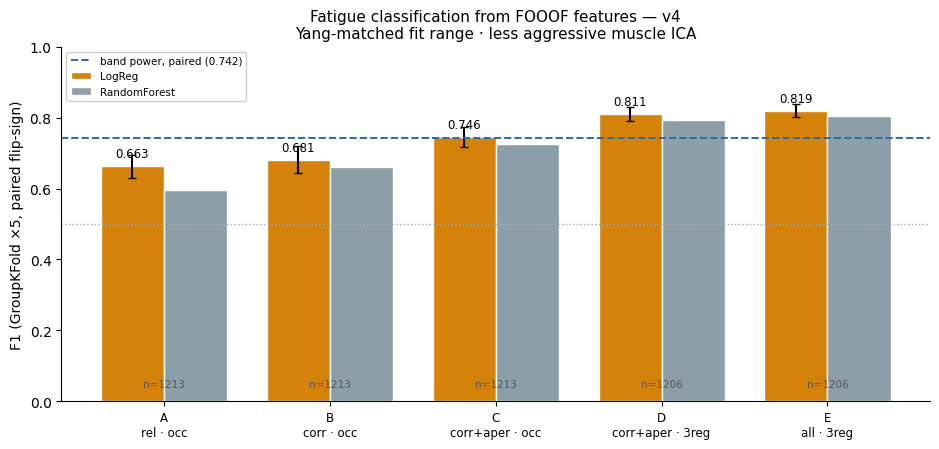

In [15]:
NB4_M3 = 0.742     # band power, paired (NB4 Method 3) — เส้นอ้างอิงที่เทียบได้
# เส้น v2 set C (0.775) ถูกถอดออกจากกราฟ เพราะเป็นตัวเลขที่เรารู้แล้วว่ามีอคติ
# เอามาวางในกราฟที่ใช้เสนอผลจะชวนให้เข้าใจผิด · เรื่องช่วง fit มีสไลด์ของตัวเองอยู่แล้ว

labels = list(results.keys())
vlr = [results[k]['lr'].mean() for k in labels]
elr = [results[k]['lr'].std()  for k in labels]
vrf = [results[k]['rf'].mean() for k in labels]
ns  = [results[k]['n'] for k in labels]
x   = np.arange(len(labels)); wd = 0.38

fig, ax = plt.subplots(figsize=(9.5, 4.6))
b1 = ax.bar(x - wd/2, vlr, wd, yerr=elr, capsize=3, label='LogReg',
            color='#d4820a', edgecolor='white')
b2 = ax.bar(x + wd/2, vrf, wd, label='RandomForest',
            color='#8c9ea8', edgecolor='white')
ax.axhline(NB4_M3, color='#2b6ca3', ls='--', lw=1.4,
           label=f'band power, paired ({NB4_M3:.3f})')
ax.axhline(0.5, color='#aaa', ls=':', lw=1)

for bar, v in zip(b1, vlr):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.025, f'{v:.3f}',
            ha='center', fontsize=8.5)
for i, n in enumerate(ns):
    ax.text(i, 0.04, f'n={n}', ha='center', fontsize=7.5, color='#555')

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylim(0, 1); ax.set_ylabel('F1 (GroupKFold ×5, paired flip-sign)')
# v4 ใช้ find_bads_muscle(threshold=0.9) ซึ่ง "ลบน้อยลง" กว่าค่าปริยาย 0.5 ไม่ใช่เข้มขึ้น
ax.set_title('Fatigue classification from FOOOF features — v4\n'
             "Yang-matched fit range · less aggressive muscle ICA",
             fontsize=11)
ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('outputs/nb5c_v4_comparison.png', dpi=150)
plt.show()

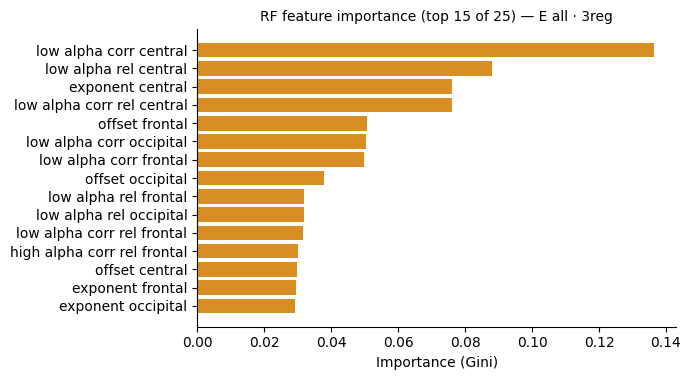

         feature_set  n_features  n_pairs  F1_LR  F1_LR_sd  F1_RF  perm_chance  perm_p
       A — rel · occ           2     1213 0.6629    0.0318 0.5945       0.4780   0.005
      B — corr · occ           2     1213 0.6810    0.0377 0.6605       0.4822   0.005
 C — corr+aper · occ           4     1213 0.7455    0.0278 0.7263       0.4881   0.005
D — corr+aper · 3reg          12     1206 0.8107    0.0201 0.7947       0.4931   0.005
      E — all · 3reg          24     1206 0.8190    0.0182 0.8039       0.4951   0.005

Best: E all · 3reg — LR F1 = 0.819
Reference — NB4 Method 3 (band power, all channels, paired): 0.742
Saved: outputs/nb5c_v4_summary.csv


In [16]:
# ข้อควรรู้สองเรื่องถ้าถูกถามถึงรูปนี้
#  1. RF fit บนข้อมูลทั้งหมด ไม่ได้แยก test fold และ Gini importance เชื่อไม่ได้มาก
#     เมื่อ feature สัมพันธ์กันเองสูง (สามบริเวณวัดของคล้ายกัน) ใช้ดูคร่าว ๆ เท่านั้น
#     อย่าสรุปว่าตัวไหนสำคัญที่สุด · รูปนี้ไม่ได้อยู่ในสไลด์
#  2. ทำไมใช้ F1 ไม่ใช้ accuracy — สองคลาสสมดุลกันอยู่แล้วเพราะสุ่มกลับเครื่องหมาย
#     ค่าสองตัวจึงใกล้กันมาก ใช้ F1 เพื่อให้เทียบกับ NB4 และ NB5a ได้ตรง
best = max(results, key=lambda k: results[k]['lr'].mean())
cols = feat_sets[best]
X, y, g = make_XyG(d, cols)
rf.fit(X, y)
names = [c.replace('_', ' ').replace('ap ', '') for c in cols] + ['task (EO)']
imps  = rf.named_steps['clf'].feature_importances_
order = np.argsort(imps)[-15:]

fig, ax = plt.subplots(figsize=(7, max(3, len(order)*0.26)))
ax.barh([names[i] for i in order], imps[order], color='#d4820a', alpha=0.9)
ax.set_xlabel('Importance (Gini)')
ax.set_title(f"RF feature importance (top {len(order)} of {len(names)}) — "
             f"{best.replace(chr(10),' ')}", fontsize=10)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('outputs/nb5c_v4_importance.png', dpi=150)
plt.show()

summary = pd.DataFrame([{
    'feature_set': k.replace('\n',' — '), 'n_features': results[k]['k'],
    'n_pairs': results[k]['n'],
    'F1_LR': results[k]['lr'].mean(), 'F1_LR_sd': results[k]['lr'].std(),
    'F1_RF': results[k]['rf'].mean(),
    'perm_chance': perm[k]['chance'], 'perm_p': perm[k]['p'],
} for k in results])
print(summary.round(4).to_string(index=False))
print(f"\nBest: {best.replace(chr(10),' ')} — LR F1 = {results[best]['lr'].mean():.3f}")
print(f"Reference — NB4 Method 3 (band power, all channels, paired): {NB4_M3:.3f}")
summary.to_csv('outputs/nb5c_v4_summary.csv', index=False)
print("Saved: outputs/nb5c_v4_summary.csv")